# Prédire le diabète chez un groupe de personnes

## Introduction

Le jeu de données que nous allons étudier provient du National Institute of Diabetes and Digestive and Kidney Diseases et est disponible au format CSV sur Kaggle. Il a pour objectif de prédire, à partir de mesures médicales, si une patiente est atteinte de diabète. Tous les patients inclus sont des femmes d’au moins 21 ans et d’origine indienne Pima.

Le jeu de données comprend plusieurs variables prédictives telles que le nombre de grossesses, l’IMC, le taux d’insuline, l’âge, ainsi qu’une variable cible Outcome indiquant la présence ou l’absence de diabète.

## Exploration et compréhension des données

In [3]:
# Importation des bibliothèques utile 

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

### Visualisation générale du jeu de données

In [4]:
df = pd.read_csv("diabetes.csv") # on lit le fichier diabetes.csv et on le stock dans df

In [5]:
df.head(10) # on affiche les 10 première valeurs

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [6]:
# Affiche la dimension du data frame.
df.shape

(768, 9)

Nous avons dans notre jeu de données 768 lignes/observations, elles correspondent au nombres de personne testé.

<u>**Compréhension des différentes variables explicatives potentielle**<u>

Dans ce jeux de données on a donc 8 variables potentiellement explicatives : Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin	BMI, DiabetesPedigreeFunction et Age.

Pregnancies corresponds au nombres de grossesses. 

Glucose corresponds à une mesure de la glycèmie elle est mesuré en faisant boire une solution contenant du glucose et en mesurant le taux de sucre dans le sang deux heure plus tard via une prise de sang. Ce test sert notamment à voir comment l'organisme gère le glucose et peut aider au dépistage du prédiabète ou du diabète. La mesure ici est en mg/dl.

BloodPresure correspond ici à la pression artérielle diastolique, c’est-à-dire la pression dans les artères quand le cœur se relâche entre deux battements. Elle est mesuré en mmHg.

SkinThickness correspond à l’épaisseur du pli cutané au niveau du triceps, mesurée en millimètres (mm).
On pince doucement la peau et la graisse sous-cutanée à l’arrière du bras, au niveau du triceps, puis on mesure l’épaisseur avec un instrument appelé pince à plis cutanés (adipomètre).
Cette mesure donne donc une indication sur la quantité de graisse sous-cutanée.
Elle est mesuré ici en mm.

Insulin correspond au taux d’insuline mesuré dans le sérum sanguin, 2 heures après une charge en glucose, généralement lors d’un test de tolérance au glucose.
L’insuline est une hormone produite par le pancréas. Elle aide le glucose présent dans le sang à entrer dans les cellules pour être utilisé comme énergie.
La mesure se fait en µU/mL.

BMI correspond à l’IMC (Indice de Masse Corporelle). L’IMC donne une estimation de la corpulence d’une personne, mais il ne distingue pas directement la masse grasse de la masse musculaire.
Il se calcule via la formule :

IMC = poids (kg) / taille² (m²)

et se mesure donc en kg/m².

DiabetesPedigreeFunction correspond à un score qui représente l’importance des antécédents familiaux de diabète, en tenant compte du lien de parenté.
L’idée est que si plusieurs proches d’une personne ont eu un diabète, surtout des proches génétiquement proches comme les parents ou les frères et sœurs, le score peut être plus élevé.

Et enfin Age qui est l'âge de la personne en année.

Nous avons aussi notre variable d'intérêt qui est ici Outcome.
Elle vaut 1 si la personne est effectivement diabètique et 0 sinon.

<u>**Détection de valeurs aberrantes / manquantes**<u>

In [7]:
# On regarde si il y a des valeurs manquantes.
df.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Aucune valeur n’est actuellement encodée comme manquante (NaN). Il reste cependant à vérifier la présence de valeurs numériques impossibles ou incohérentes pouvant représenter des données manquantes.

In [8]:
# Permet de verifier si des observations sont les mêmes.
df.duplicated().sum()

np.int64(0)

Aucune observation n'est dupliquées.

In [9]:
# Permet de verifier si des valeurs sont <0.
print((df < 0).any())

Pregnancies                 False
Glucose                     False
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool


Aucune des valeurs n'est négatif ce qui est conforme à la réalité de chacune des mesures.

In [10]:
print((df == 0).any())

Pregnancies                  True
Glucose                      True
BloodPressure                True
SkinThickness                True
Insulin                      True
BMI                          True
DiabetesPedigreeFunction    False
Age                         False
Outcome                      True
dtype: bool


L’exploration des données met en évidence plusieurs valeurs égales à 0 pour les variables Glucose, BloodPressure, SkinThickness, Insulin et BMI. Ces valeurs ne sont pas plausibles pour ces mesures et devront donc être considérées comme des valeurs manquantes. Une étape de nettoyage et de traitement des données manquantes est nécessaire avant l’entraînement des modèles.

<u>**Remplacement**<u>

L'idée va être de remplacer ces valeurs égales à 0 pour les variables Glucose, BloodPressure, SkinThickness, Insulin et BMI par NaN.
pour les différencier de variables pouvant véritablement être égale à 0.
Nous verrons ensuite la manière dont nous les gérerons.

In [11]:
# Remplacement.
cols = ["Glucose", "BloodPressure",  "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)

In [12]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1
5,5,116.0,74.0,NaN,NaN,25.6,0.201,30,0
6,3,78.0,50.0,32.0,88.0,31.0,0.248,26,1
7,10,115.0,NaN,NaN,NaN,35.3,0.134,29,0
8,2,197.0,70.0,45.0,543.0,30.5,0.158,53,1
9,8,125.0,96.0,NaN,NaN,NaN,0.232,54,1


In [13]:
val_manquante = pd.DataFrame({
    "Nombre de valeurs manquantes": df[cols].isna().sum(),
    "Pourcentage": df[cols].isna().mean() * 100
})

val_manquante

,Nombre de valeurs manquantes,Pourcentage
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


La proportion de données manquantes varie fortement selon les variables. Elle reste faible pour Glucose, BMI et BloodPressure, mais devient importante pour SkinThickness et particulièrement pour Insulin, dont près de la moitié des observations sont manquantes.

Une stratégie unique d’imputation pour l’ensemble des variables pourrait donc être inadaptée. Plusieurs approches seront comparées.

<u>**Analyse des distributions et des répartitions**<u>

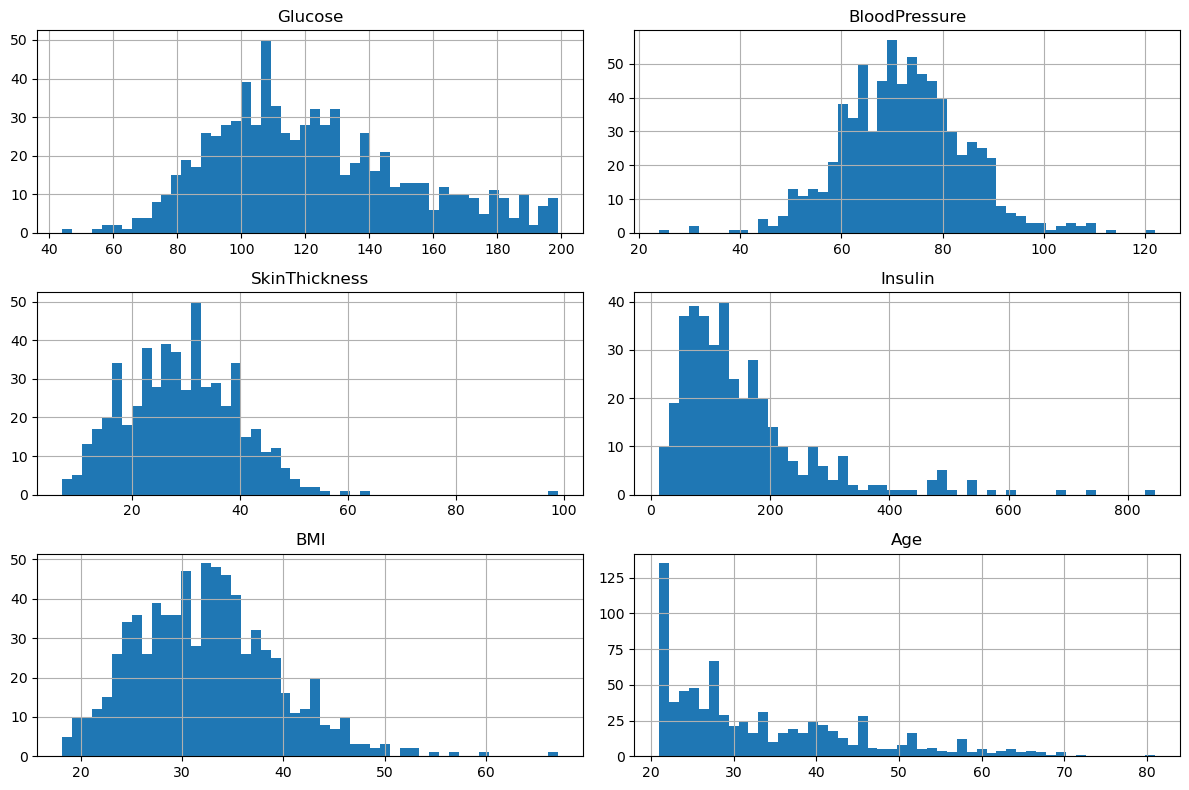

In [14]:
df[["Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "Age"]].hist(
    figsize=(12, 8),
    bins=50
)

plt.tight_layout()
plt.show()

In [15]:
variables = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "Age"
]

df[variables].skew()

Glucose          0.530989
BloodPressure    0.134153
SkinThickness    0.690619
Insulin          2.166464
BMI              0.593970
Age              1.129597
dtype: float64

L’analyse des histogrammes et des coefficients d’asymétrie montre que BloodPressure présente une distribution relativement symétrique. Glucose, SkinThickness et BMI présentent une asymétrie modérée vers les valeurs élevées, tandis que cette asymétrie est plus marquée pour Age et particulièrement forte pour Insulin. Ces distributions asymétriques, notamment celle d’Insulin, suggèrent qu’il faudra privilégier des méthodes de prétraitement robustes aux valeurs extrêmes.

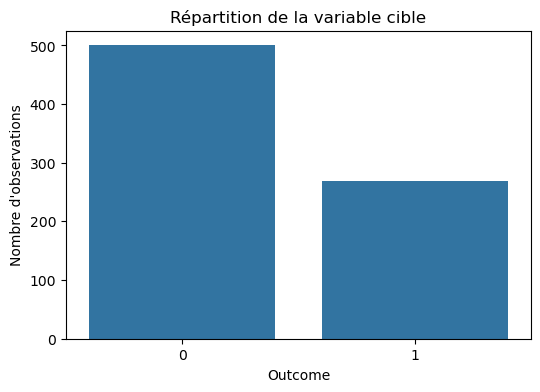

In [16]:
plt.figure(figsize=(6,4))
sns.countplot(x="Outcome", data=df)
plt.xlabel("Outcome")
plt.ylabel("Nombre d'observations")
plt.title("Répartition de la variable cible")
plt.show()

In [17]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


In [18]:
print(df["Outcome"].value_counts(normalize=True) * 100)

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


On observe un déséquilibre modéré de la variable cible : environ 65 % des observations correspondent à des personnes non diabétiques, contre 35 % de personnes diabétiques. Il y a ainsi environ 1,9 fois plus d’observations dans la classe 0 que dans la classe 1. Ce déséquilibre devra être pris en compte lors de l’évaluation des modèles, car une bonne accuracy globale peut masquer de mauvaises performances sur la classe minoritaire. Il sera donc pertinent d’examiner également des métriques telles que le rappel, la précision et le F1-score.

Par exemple, un modèle qui prédit toujours Outcome = 0 aurait déjà :

$\frac{500}{768}\approx 65\%$

d’accuracy, alors qu’il serait complètement inutile pour détecter le diabète.

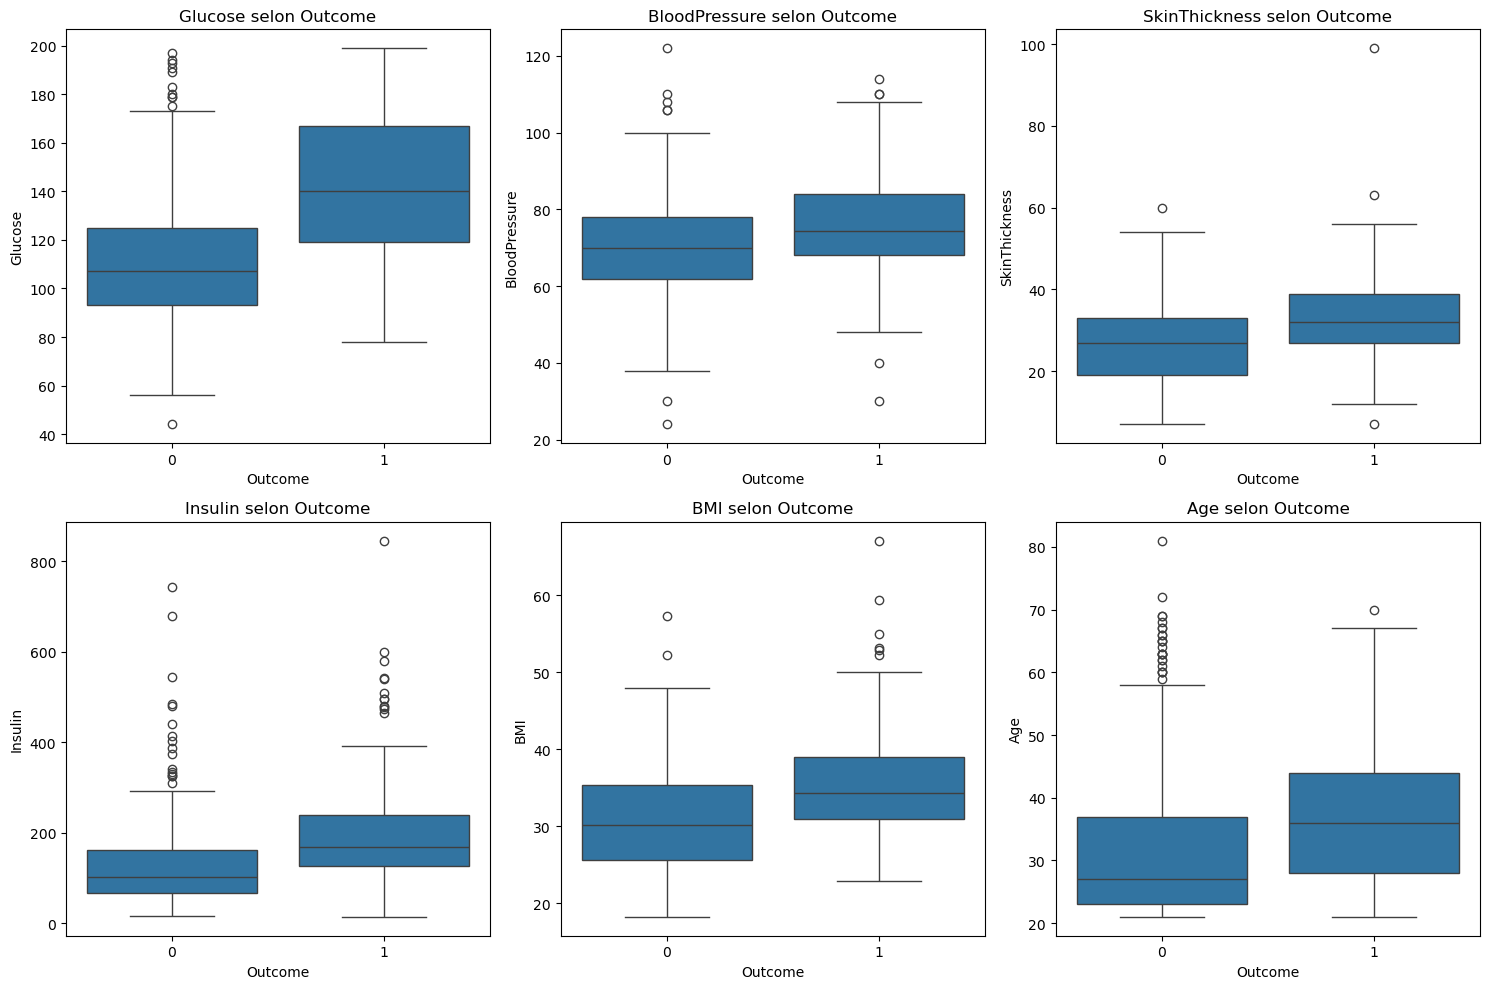

In [19]:
variables = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "Age"
]

plt.figure(figsize=(15, 10))

for i, var in enumerate(variables, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x="Outcome", y=var, data=df)
    plt.title(f"{var} selon Outcome")

plt.tight_layout()
plt.show()

Les boxplots montrent des différences de distribution entre les groupes Outcome = 0 et Outcome = 1. La différence est particulièrement visible pour Glucose, dont la médiane est nettement plus élevée chez les personnes diabétiques. Des valeurs médianes plus élevées sont également observées pour BMI, Age, Insulin et, dans une moindre mesure, SkinThickness. En revanche, les distributions de BloodPressure semblent davantage se chevaucher.  
Plusieurs valeurs se situent au-delà des moustaches des boxplots. Elles correspondent à des observations atypiques au regard de la distribution.

<Axes: >

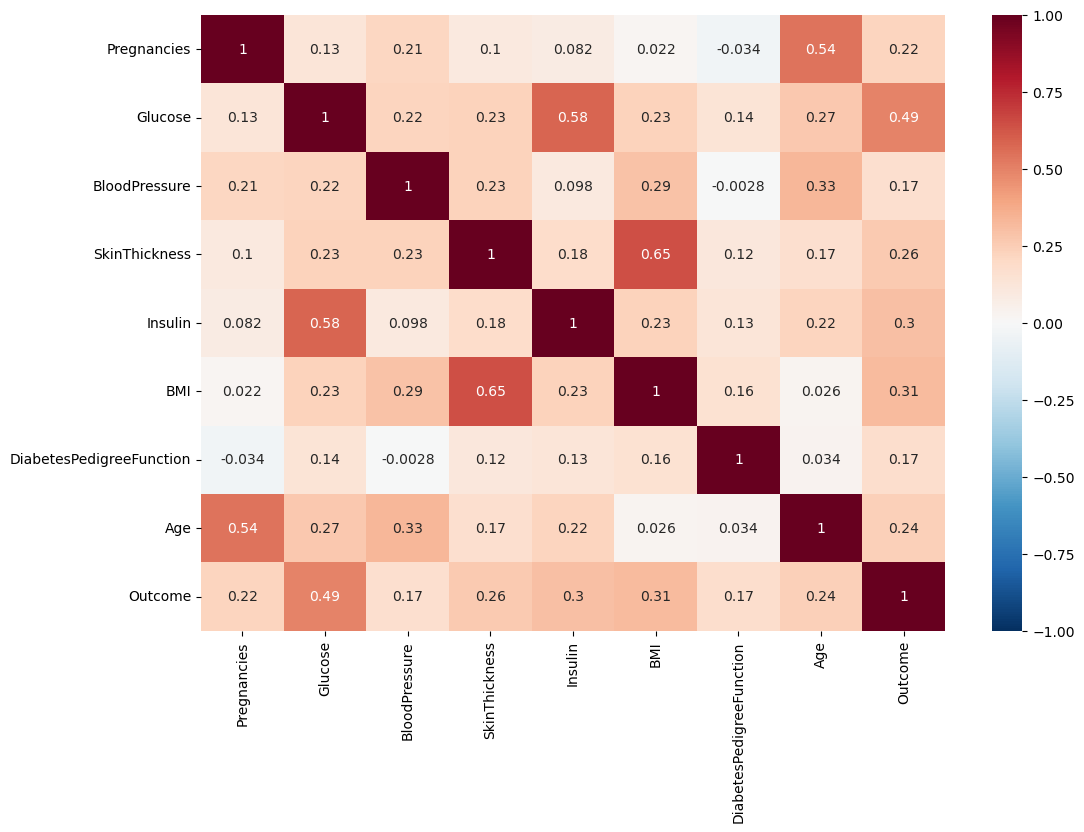

In [20]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),vmin = -1.0, center = 0, cmap='RdBu_r', annot=True)

La matrice met en évidence plusieurs corrélations positives entre variables explicatives, notamment entre BMI et SkinThickness $(r=0.65)$, entre Glucose et Insulin $(r=0.58)$ et entre Pregnancies et Age $(r=0.54)$.  
Concernant la variable cible Outcome, Glucose présente la corrélation linéaire la plus importante $(r=0.49)$. BMI, Insulin, SkinThickness et Age présentent des associations positives plus modérées. Les corrélations de BloodPressure et DiabetesPedigreeFunction avec Outcome sont plus faibles.  
La corrélation impliquant Insulin doit toutefois être interprétée avec prudence en raison de la forte proportion de valeurs manquantes pour cette variable.

<u>**Motif des valeurs manquantes**<u>

In [21]:
patterns1 = df[cols].isna().value_counts().reset_index(name="Nombre")
patterns1.head(11)

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Nombre
0,False,False,False,False,False,392
1,False,False,True,True,False,192
2,False,False,False,True,False,140
3,False,True,True,True,False,26
4,False,True,True,True,True,7
5,True,False,False,True,False,4
6,False,False,True,True,True,2
7,False,True,False,True,False,2
8,False,False,False,False,True,1
9,False,False,False,True,True,1


L’analyse des motifs de données manquantes montre qu’elles ne sont pas réparties de manière isolée. En particulier, toutes les observations présentant une valeur manquante pour SkinThickness présentent également une valeur manquante pour Insulin. Les valeurs manquantes de BloodPressure apparaissent également en combinaison avec une absence d’Insulin.

In [22]:
missing_by_outcome = (
    df.groupby("Outcome")[cols]
      .apply(lambda x: x.isna().mean() * 100)
)

missing_by_outcome

,Glucose,BloodPressure,SkinThickness,Insulin,BMI
Outcome,,,,,
0,0.600000,3.800000,27.800000,47.200000,1.800000
1,0.746269,5.970149,32.835821,51.492537,0.746269


Les proportions de valeurs manquantes restent globalement du même ordre entre les deux classes de Outcome. On observe néanmoins une fréquence légèrement plus élevée de valeurs manquantes pour BloodPressure, SkinThickness et Insulin chez les personnes diabétiques. Les écarts les plus importants concernent SkinThickness et Insulin, avec environ 5 et 4 points de pourcentage supplémentaires. Cette analyse descriptive suggère que le mécanisme de données manquantes pourrait ne pas être totalement indépendant de Outcome, mais elle ne permet pas à elle seule de conclure à une association statistiquement significative.

In [23]:
from scipy.stats import chi2_contingency

for var in ["BloodPressure", "SkinThickness", "Insulin"]:
    table = pd.crosstab(df["Outcome"], df[var].isna())
    chi2, p, dof, expected = chi2_contingency(table)

    print(var)
    print("p-value :", p)
    print()

BloodPressure
p-value : 0.23287893906822257

SkinThickness
p-value : 0.16918629466779417

Insulin
p-value : 0.28975431574224064



Les tests du khi-deux ne mettent pas en évidence d’association statistiquement significative entre Outcome et la présence de valeurs manquantes pour BloodPressure $(p=0.233)$, SkinThickness $(p=0.169)$ et Insulin $(p=0.290)$. On ne dispose donc pas d’éléments suffisants pour conclure que le mécanisme de valeurs manquantes de ces variables dépend de la variable cible.

## Prétraitement et modélisation

In [24]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

Stratégie de référence
Une première stratégie consiste à imputer l'ensemble des valeurs manquantes par la médiane de chaque variable. Cette méthode simple et robuste aux valeurs extrêmes servira de référence pour comparer des méthodes d'imputation plus élaborées.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline_median = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [26]:
from sklearn.model_selection import cross_validate

scores_median = cross_validate(
    pipeline_median,
    X_train,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        metric,
        scores_median[f"test_{metric}"].mean()
    )

accuracy 0.7795652173913042
precision 0.7338250644532478
recall 0.5869512195121952
f1 0.6499789349318938
roc_auc 0.8348829268292682


In [27]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_median[f"test_{metric}"].mean()
    std = scores_median[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.780 ± 0.022
precision : 0.734 ± 0.055
recall : 0.587 ± 0.044
f1 : 0.650 ± 0.031
roc_auc : 0.835 ± 0.014


Cette première stratégie constitue notre modèle de référence. La ROC-AUC moyenne de 0,835 indique une capacité de discrimination intéressante et relativement stable entre les folds. Le rappel reste toutefois limité à environ 0,59 : avec le seuil de classification par défaut, une proportion importante des observations positives n'est pas détectée. Ces résultats serviront de référence pour comparer les autres stratégies.

In [28]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

pipeline_knn_imputer = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("model", LogisticRegression(max_iter=1000))
])

In [29]:
scores_knn_imputer = cross_validate(
    pipeline_knn_imputer,
    X_train,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        metric,
        scores_knn_imputer[f"test_{metric}"].mean()
    )

accuracy 0.7847676161919039
precision 0.7455794504181601
recall 0.591829268292683
f1 0.6569260682155871
roc_auc 0.8358829268292682


In [30]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_knn_imputer[f"test_{metric}"].mean()
    std = scores_knn_imputer[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.785 ± 0.016
precision : 0.746 ± 0.050
recall : 0.592 ± 0.048
f1 : 0.657 ± 0.023
roc_auc : 0.836 ± 0.014


L'imputation par KNN conduit à une légère amélioration de plusieurs métriques par rapport à l'imputation médiane. Toutefois, les écarts restent faibles au regard de la variabilité observée en validation croisée. Il n'apparaît donc pas de gain net justifiant à lui seul l'utilisation d'une méthode d'imputation plus complexe.

In [31]:
X_train_no_insulin = X_train.drop(columns=["Insulin"])

In [32]:
scores_no_insulin = cross_validate(
    pipeline_median,
    X_train_no_insulin,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        metric,
        scores_no_insulin[f"test_{metric}"].mean()
    )

accuracy 0.7812893553223388
precision 0.7355794504181601
recall 0.591829268292683
f1 0.6533966564508813
roc_auc 0.8365886178861788


In [33]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_no_insulin[f"test_{metric}"].mean()
    std = scores_no_insulin[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.781 ± 0.020
precision : 0.736 ± 0.053
recall : 0.592 ± 0.048
f1 : 0.653 ± 0.029
roc_auc : 0.837 ± 0.012


La suppression d'Insulin n'entraîne pas de dégradation notable des performances. Malgré l'information potentiellement apportée par cette variable, près de la moitié de ses valeurs sont manquantes. Dans cette configuration, son exclusion permet de simplifier le problème sans perte prédictive.

In [34]:
X_train_no_insulin_skin = X_train.drop(
    columns=["Insulin", "SkinThickness"]
)

In [35]:

scores_no_insulin_skin = cross_validate(
    pipeline_median,
    X_train_no_insulin_skin,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        metric,
        scores_no_insulin_skin[f"test_{metric}"].mean()
    )

accuracy 0.7847676161919039
precision 0.749547704386414
recall 0.5868292682926829
f1 0.6552610188494149
roc_auc 0.8367886178861788


In [36]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_no_insulin_skin[f"test_{metric}"].mean()
    std = scores_no_insulin_skin[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.785 ± 0.015
precision : 0.750 ± 0.052
recall : 0.587 ± 0.043
f1 : 0.655 ± 0.017
roc_auc : 0.837 ± 0.013


Le retrait simultané d'Insulin et de SkinThickness, les deux variables présentant le plus de données manquantes, n'entraîne toujours pas de diminution notable des performances. Cette stratégie permet de réduire la complexité du prétraitement tout en conservant des performances comparables. Elle sera donc retenue pour la comparaison des modèles de classification car plus simple.

In [37]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

pipeline_iterative = Pipeline([
    ("imputer", IterativeImputer(
        max_iter=10,
        random_state=42
    )),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [38]:
scores_iterative = cross_validate(
    pipeline_iterative,
    X_train,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        metric,
        scores_iterative[f"test_{metric}"].mean()
    )

accuracy 0.7812893553223388
precision 0.7385503530914281
recall 0.586829268292683
f1 0.6517010326354908
roc_auc 0.8345593495934958


In [39]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_iterative[f"test_{metric}"].mean()
    std = scores_iterative[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.781 ± 0.020
precision : 0.739 ± 0.053
recall : 0.587 ± 0.043
f1 : 0.652 ± 0.027
roc_auc : 0.835 ± 0.015


L'imputation itérative multivariée n'améliore pas sensiblement les performances par rapport à l'imputation médiane. Une méthode plus complexe ne semble pas apporter de gain.

In [40]:
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

scores_knn_model = cross_validate(
    pipeline_knn_model,
    X_train_no_insulin_skin,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_knn_model[f"test_{metric}"].mean()
    std = scores_knn_model[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.745 ± 0.014
precision : 0.662 ± 0.046
recall : 0.567 ± 0.070
f1 : 0.606 ± 0.030
roc_auc : 0.799 ± 0.020


Dans sa configuration initiale avec (k=5), le KNN obtient des performances inférieures à celles de la régression logistique sur l'ensemble des métriques étudiées. Le rappel présente également une plus grande variabilité entre les folds. Ces résultats suggèrent que cette configuration du KNN est moins adaptée aux données, mais une optimisation du nombre de voisins k reste nécessaire avant de conclure.

In [41]:
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

scores_rf = cross_validate(
    pipeline_rf,
    X_train_no_insulin_skin,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean = scores_rf[f"test_{metric}"].mean()
    std = scores_rf[f"test_{metric}"].std()

    print(f"{metric} : {mean:.3f} ± {std:.3f}")

accuracy : 0.755 ± 0.028
precision : 0.680 ± 0.060
recall : 0.577 ± 0.066
f1 : 0.621 ± 0.043
roc_auc : 0.816 ± 0.016


La Random Forest obtient des performances supérieures au KNN initial, mais reste en retrait par rapport à la régression logistique. L'utilisation d'un modèle non linéaire plus complexe n'apporte donc pas, dans sa configuration initiale, d'amélioration notable.

In [42]:
from sklearn.model_selection import GridSearchCV

pipeline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    pipeline_lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring="roc_auc"
)

grid_lr.fit(
    X_train_no_insulin_skin,
    y_train
)

print("Meilleur C :", grid_lr.best_params_)
print("Meilleure ROC-AUC :", grid_lr.best_score_)

Meilleur C : {'model__C': 0.1}
Meilleure ROC-AUC : 0.8381886178861789


In [43]:
results = grid_lr.cv_results_

for C, mean, std in zip(
    results["param_model__C"],
    results["mean_test_score"],
    results["std_test_score"]
):
    print(f"C={C} : ROC-AUC = {mean:.3f} ± {std:.3f}")

C=0.01 : ROC-AUC = 0.838 ± 0.022
C=0.1 : ROC-AUC = 0.838 ± 0.014
C=1.0 : ROC-AUC = 0.837 ± 0.013
C=10.0 : ROC-AUC = 0.837 ± 0.013
C=100.0 : ROC-AUC = 0.836 ± 0.013


La recherche d'hyperparamètres sélectionne (C=0.1), avec une ROC-AUC moyenne d'environ 0,838. Cependant, les performances varient très peu entre les différentes valeurs de (C).

In [44]:
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21]
}

grid_knn = GridSearchCV(
    pipeline_knn_model,
    param_grid=param_grid_knn,
    cv=5,
    scoring="roc_auc"
)

grid_knn.fit(
    X_train_no_insulin_skin,
    y_train
)

print("Meilleur k :", grid_knn.best_params_)
print("Meilleure ROC-AUC :", grid_knn.best_score_)

Meilleur k : {'model__n_neighbors': 15}
Meilleure ROC-AUC : 0.821550406504065


In [45]:
results_knn = grid_knn.cv_results_

for k, mean, std in zip(
    results_knn["param_model__n_neighbors"],
    results_knn["mean_test_score"],
    results_knn["std_test_score"]
):
    print(f"k={k} : ROC-AUC = {mean:.3f} ± {std:.3f}")

k=3 : ROC-AUC = 0.781 ± 0.024
k=5 : ROC-AUC = 0.799 ± 0.020
k=7 : ROC-AUC = 0.807 ± 0.023
k=9 : ROC-AUC = 0.810 ± 0.031
k=11 : ROC-AUC = 0.816 ± 0.029
k=15 : ROC-AUC = 0.822 ± 0.029
k=21 : ROC-AUC = 0.821 ± 0.025


Le nombre de voisins influence sensiblement les performances du KNN. La ROC-AUC augmente progressivement lorsque (k) passe de 3 à 15, puis semble se stabiliser. Le meilleur résultat est obtenu pour (k=15), avec une ROC-AUC d'environ 0,822. Cette optimisation améliore donc nettement le KNN, mais ses performances restent inférieures à la régression logistique.

In [46]:
param_grid_rf = {
    "model__max_depth": [None, 3, 5, 8],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", None]
}

grid_rf = GridSearchCV(
    pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_rf.fit(
    X_train_no_insulin_skin,
    y_train
)

print("Meilleurs paramètres :", grid_rf.best_params_)
print("Meilleure ROC-AUC :", grid_rf.best_score_)

Meilleurs paramètres : {'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}
Meilleure ROC-AUC : 0.8291772357723577


L'optimisation des hyperparamètres améliore la Random Forest, la ROC-AUC atteint environ 0,829. Malgré cette amélioration, la régression logistique conserve la ROC-AUC moyenne la plus élevée en validation croisée.

Au regard des résultats de validation croisée, la régression logistique avec (C=0.1) est retenue comme modèle final. Elle associe la meilleure ROC-AUC observée à une structure relativement simple et interprétable. Le jeu de test, resté en dehors de l'entraînement et de la sélection des hyperparamètres, est maintenant utilisé pour l'évaluation finale.

In [47]:
final_model = grid_lr.best_estimator_

In [48]:
X_test_no_insulin_skin = X_test.drop(
    columns=["Insulin", "SkinThickness"]
)

In [49]:
y_pred = final_model.predict(X_test_no_insulin_skin)

y_proba = final_model.predict_proba(
    X_test_no_insulin_skin
)[:, 1]

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision :", precision_score(y_test, y_pred))
print("Recall :", recall_score(y_test, y_pred))
print("F1 :", f1_score(y_test, y_pred))
print("ROC-AUC :", roc_auc_score(y_test, y_proba))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.7291666666666666
Precision : 0.6363636363636364
Recall : 0.5223880597014925
F1 : 0.5737704918032787
ROC-AUC : 0.8237611940298507

Matrice de confusion :
[[105  20]
 [ 32  35]]


Sur le jeu de test indépendant, le modèle final obtient une ROC-AUC de 0,824, proche de la valeur observée en validation croisée (environ 0,838). La capacité du modèle à distinguer les deux classes semble donc relativement stable sur des données non utilisées pour sa sélection. En revanche, les performances obtenues avec le seuil de classification par défaut de 0,5 sont plus modestes : l'accuracy est de 72,9 %, la précision de 63,6 %, le rappel de 52,2 % et le F1-score de 0,574.

La matrice de confusion montre que 105 observations négatives et 35 observations positives sont correctement classées. Le modèle produit cependant 20 faux positifs et surtout 32 faux négatifs. Ainsi, près de la moitié des observations positives du jeu de test ne sont pas détectées. Le rappel constitue donc la principale limite du modèle avec le seuil de décision actuel.

Ces résultats montrent qu'une bonne capacité de discrimination globale, mesurée par la ROC-AUC, ne garantit pas nécessairement de bonnes performances de classification pour un seuil donné.